In [5]:
# ============================================================
# 0.  Environment & Imports
# ============================================================
import os
import sys
import math
import json
import random
import warnings
import gc
import time
from datetime import datetime
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split, Subset
from torchvision import transforms, models
from torchvision.models import ResNet18_Weights

from opacus import PrivacyEngine
from opacus.validators import ModuleValidator

warnings.filterwarnings("ignore")

# GPU setup
os.environ["CUDA_VISIBLE_DEVICES"] = "1"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

# ============================================================
# 1.  UTKFace Dataset
# ============================================================
IMAGE_DIR = Path("project/data/UTKFace")
BATCH_SIZE = 16
NUM_WORKERS = 4
RANDOM_SEED = 42

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

class UTKFaceDataset(Dataset):
    def __init__(self, root_dir, transform=None, filter_gender=None):
        self.root_dir = Path(root_dir)
        self.transform = transform
        self.samples = []
        image_files = list(self.root_dir.rglob("*.jpg")) + list(self.root_dir.rglob("*.JPG"))
        for img_path in image_files:
            try:
                filename = img_path.stem
                if '.chip' in filename:
                    filename = filename.replace('.chip', '')
                parts = filename.split('_')
                if len(parts) >= 2:
                    age = int(parts[0])
                    gender = int(parts[1])
                    if filter_gender is not None and gender != filter_gender:
                        continue
                    self.samples.append({
                        'path': str(img_path),
                        'age': age,
                        'gender': gender,
                    })
            except:
                pass
        print(f"Loaded {len(self.samples)} samples")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        sample = self.samples[idx]
        image = Image.open(sample['path']).convert('RGB')
        if self.transform:
            image = self.transform(image)
        age = torch.tensor(sample['age'], dtype=torch.float32)
        gender = torch.tensor(sample['gender'], dtype=torch.long)
        return image, age, gender

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

full_dataset = UTKFaceDataset(IMAGE_DIR, transform=train_transform)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size],
                                          generator=torch.Generator().manual_seed(RANDOM_SEED))

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=True)

# ============================================================
# 2.  OPACUS-COMPATIBLE RESNET (No in-place operations)
# ============================================================

class OpacusBasicBlock(nn.Module):
    """BasicBlock without any in-place operations."""
    expansion = 1

    def __init__(self, inplanes, planes, stride=1, downsample=None):
        super().__init__()
        self.conv1 = nn.Conv2d(inplanes, planes, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.GroupNorm(min(32, planes), planes, affine=True)
        self.relu = nn.ReLU(inplace=False)  # Critical: inplace=False
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.GroupNorm(min(32, planes), planes, affine=True)
        self.downsample = downsample
        self.stride = stride

    def forward(self, x):
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        if self.downsample is not None:
            identity = self.downsample(x)

        # CRITICAL FIX: Use out = out + identity (non-in-place) instead of out += identity
        out = out + identity
        out = self.relu(out)

        return out


class OpacusResNet(nn.Module):
    """ResNet-18 compatible with Opacus (no in-place ops)."""
    def __init__(self, num_classes=1):
        super().__init__()
        self.inplanes = 64

        self.conv1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.GroupNorm(min(32, 64), 64, affine=True)
        self.relu = nn.ReLU(inplace=False)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

        self.layer1 = self._make_layer(64, 2, stride=1)
        self.layer2 = self._make_layer(128, 2, stride=2)
        self.layer3 = self._make_layer(256, 2, stride=2)
        self.layer4 = self._make_layer(512, 2, stride=2)

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(512, num_classes)

    def _make_layer(self, planes, blocks, stride=1):
        downsample = None
        if stride != 1 or self.inplanes != planes * OpacusBasicBlock.expansion:
            downsample = nn.Sequential(
                nn.Conv2d(self.inplanes, planes * OpacusBasicBlock.expansion,
                          kernel_size=1, stride=stride, bias=False),
                nn.GroupNorm(min(32, planes * OpacusBasicBlock.expansion), 
                            planes * OpacusBasicBlock.expansion, affine=True),
            )

        layers = []
        layers.append(OpacusBasicBlock(self.inplanes, planes, stride, downsample))
        self.inplanes = planes * OpacusBasicBlock.expansion
        for _ in range(1, blocks):
            layers.append(OpacusBasicBlock(self.inplanes, planes))

        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)

        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)

        return x.squeeze(1)


def load_pretrained_weights_to_opacus_model(opacus_model, pretrained_state_dict):
    """
    Transfer pretrained weights from standard ResNet to Opacus-compatible model.
    This matches layer names and handles the GroupNorm vs BatchNorm difference.
    """
    opacus_state = opacus_model.state_dict()
    transferred = 0
    
    for name, param in pretrained_state_dict.items():
        if name in opacus_state and opacus_state[name].shape == param.shape:
            opacus_state[name] = param.clone()
            transferred += 1
    
    opacus_model.load_state_dict(opacus_state)
    print(f"✓ Transferred {transferred} pretrained weight layers to Opacus model")
    return opacus_model


def build_model(pretrained=True):
    """
    Build Opacus‑compatible age regression model.
    If pretrained=True, loads weights from standard ResNet-18.
    """
    # Create Opacus-compatible model (GroupNorm, no in-place ops)
    model = OpacusResNet(num_classes=1).to(device)
    
    if pretrained:
        # Load standard pretrained ResNet-18
        local_weight_path = "/home/govindu.srimaan/project/data/resnet18-f37072fd.pth"
        
        if os.path.exists(local_weight_path):
            pretrained_dict = torch.load(local_weight_path, map_location='cpu')
            model = load_pretrained_weights_to_opacus_model(model, pretrained_dict)
            print(f"✓ Loaded pretrained weights from: {local_weight_path}")
        else:
            print(f"⚠ Pretrained weights not found at {local_weight_path}, training from scratch")
    
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"✓ Model built: {total_params:,} total, {trainable_params:,} trainable")
    
    # Verify Opacus compatibility
    errors = ModuleValidator.validate(model, strict=False)
    if errors:
        print(f"⚠ Found {len(errors)} issues – fixing...")
        model = ModuleValidator.fix(model)
        errors_after = ModuleValidator.validate(model, strict=False)
        print(f"  Remaining issues: {len(errors_after)}")
        assert len(errors_after) == 0, f"Unfixable issues: {errors_after}"
    else:
        print("✓ Opacus validation passed")
    
    return model

# ============================================================
# 3.  Training utilities
# ============================================================
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0.0
    for images, ages, _ in loader:
        images, ages = images.to(device), ages.to(device)
        optimizer.zero_grad()
        preds = model(images)
        loss = criterion(preds, ages)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
    return total_loss / len(loader.dataset)

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    for images, ages, _ in loader:
        images, ages = images.to(device), ages.to(device)
        preds = model(images)
        loss = criterion(preds, ages)
        total_loss += loss.item() * images.size(0)
    return total_loss / len(loader.dataset)

# ============================================================
# 4.  Baseline training (non-private)
# ============================================================
def train_baseline(epochs=10):
    print("\n" + "="*60)
    print("BASELINE TRAINING (Non-Private)")
    print("="*60)
    
    model = build_model(pretrained=True)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.L1Loss()
    best_mae = float('inf')
    
    for epoch in range(1, epochs+1):
        train_loss = train_epoch(model, train_loader, optimizer, criterion)
        val_loss = evaluate(model, val_loader, criterion)
        print(f"Baseline epoch {epoch:2d}/{epochs}: Train MAE = {train_loss:.3f}, Val MAE = {val_loss:.3f}")
        if val_loss < best_mae:
            best_mae = val_loss
            torch.save(model.state_dict(), "baseline_best.pth")
    
    return best_mae, model

# ============================================================
# 5.  DP‑SGD training (Opacus)
# ============================================================
def train_dp(epochs=10, noise_multiplier=1.0, max_grad_norm=1.0, delta=1e-5):
    print("\n" + "="*60)
    print("DP‑SGD TRAINING (Differentially Private)")
    print("="*60)
    
    model = build_model(pretrained=True)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.L1Loss()
    
    privacy_engine = PrivacyEngine()
    model, optimizer, dp_train_loader = privacy_engine.make_private(
        module=model,
        optimizer=optimizer,
        data_loader=train_loader,
        noise_multiplier=noise_multiplier,
        max_grad_norm=max_grad_norm,
    )
    
    best_mae = float('inf')
    eps_history = []
    
    for epoch in range(1, epochs+1):
        train_loss = train_epoch(model, dp_train_loader, optimizer, criterion)
        val_loss = evaluate(model, val_loader, criterion)
        eps = privacy_engine.get_epsilon(delta)
        eps_history.append(eps)
        print(f"DP epoch {epoch:2d}/{epochs}: Train MAE = {train_loss:.3f}, Val MAE = {val_loss:.3f}, ε = {eps:.2f}")
        if val_loss < best_mae:
            best_mae = val_loss
            torch.save(model.state_dict(), "dp_best.pth")
    
    return best_mae, eps_history[-1], model


# ============================================================
# 9.  WHITE-BOX AUDIT (Steinke et al. 2023, Algorithm 2) - WITH PROGRESS PRINTING
# ============================================================

def white_box_audit(model, train_loader, canary_idx, n_shadows=8, 
                    epochs=5, delta=1e-5, device='cuda'):
    """
    White-box membership inference audit using cumulative per-sample gradients.
    Implements Algorithm 2 from Steinke et al. 2023.
    """
    print("\n" + "="*60)
    print("WHITE‑BOX AUDIT (Steinke et al. 2023, Algorithm 2)")
    print("="*60)
    sys.stdout.flush()
    
    criterion = nn.L1Loss()
    scores_in, scores_out = [], []
    
    # Get canary data once
    print("Preparing canary data...")
    canary_img, canary_age, _ = train_loader.dataset.dataset[canary_idx]
    canary_img = canary_img.unsqueeze(0).to(device)
    canary_age = canary_age.to(device)
    print(f"Canary index: {canary_idx}")
    sys.stdout.flush()
    
    for shadow_id in range(n_shadows):
        print(f"\n[Shadow {shadow_id+1}/{n_shadows}] Creating model...")
        sys.stdout.flush()
        
        # Create fresh shadow model
        shadow = build_model(pretrained=True)
        optimizer = optim.Adam(shadow.parameters(), lr=1e-3)
        
        # Randomly decide if canary is in training set
        canary_in = random.random() < 0.5
        print(f"[Shadow {shadow_id+1}/{n_shadows}] Canary IN: {canary_in}")
        sys.stdout.flush()
        
        # Build training indices
        train_indices = []
        dataset_len = len(train_loader.dataset)
        
        for idx in range(dataset_len):
            actual_idx = train_loader.dataset.indices[idx] if hasattr(train_loader.dataset, 'indices') else idx
            if actual_idx == canary_idx:
                if canary_in:
                    train_indices.append(actual_idx)
            else:
                train_indices.append(actual_idx)
        
        print(f"[Shadow {shadow_id+1}/{n_shadows}] Training set size: {len(train_indices)}")
        sys.stdout.flush()
        
        # Create shadow loader
        shadow_dataset = Subset(train_loader.dataset.dataset, train_indices)
        shadow_loader = DataLoader(shadow_dataset, batch_size=BATCH_SIZE, 
                                   shuffle=True, num_workers=NUM_WORKERS)
        
        # Record initial loss for canary
        with torch.no_grad():
            init_pred = shadow(canary_img)
            init_loss = criterion(init_pred, canary_age).item()
        print(f"[Shadow {shadow_id+1}/{n_shadows}] Initial loss: {init_loss:.4f}")
        sys.stdout.flush()
        
        # Training
        shadow.train()
        cumulative_grad_norm = 0.0
        
        for epoch in range(epochs):
            batch_count = 0
            for batch_imgs, batch_ages, batch_indices in shadow_loader:
                batch_imgs, batch_ages = batch_imgs.to(device), batch_ages.to(device)
                optimizer.zero_grad()
                preds = shadow(batch_imgs)
                loss = criterion(preds, batch_ages)
                loss.backward()
                
                # Check if canary is in this batch
                canary_in_batch = canary_idx in [idx.item() for idx in batch_indices]
                
                if canary_in_batch and canary_in:
                    # Compute gradient norm
                    grad_norm = 0.0
                    for param in shadow.parameters():
                        if param.grad is not None:
                            grad_norm += param.grad.norm().item() ** 2
                    cumulative_grad_norm += np.sqrt(grad_norm)
                
                optimizer.step()
                batch_count += 1
                
                if batch_count % 50 == 0:
                    print(f"  Epoch {epoch+1}/{epochs}: Processed {batch_count} batches")
                    sys.stdout.flush()
            
            print(f"  Epoch {epoch+1}/{epochs} complete")
            sys.stdout.flush()
        
        # Final loss
        with torch.no_grad():
            final_pred = shadow(canary_img)
            final_loss = criterion(final_pred, canary_age).item()
        
        score = init_loss - final_loss
        
        if canary_in:
            scores_in.append(score)
            print(f"[Shadow {shadow_id+1}/{n_shadows}] CANARY IN - Score: {score:.4f}, Grad norm: {cumulative_grad_norm:.4f}")
        else:
            scores_out.append(score)
            print(f"[Shadow {shadow_id+1}/{n_shadows}] CANARY OUT - Score: {score:.4f}, Grad norm: {cumulative_grad_norm:.4f}")
        sys.stdout.flush()
        
        del shadow
        torch.cuda.empty_cache()
    
    # Compute epsilon
    scores_in = np.array(scores_in)
    scores_out = np.array(scores_out)
    
    print(f"\nScores IN: {scores_in}")
    print(f"Scores OUT: {scores_out}")
    sys.stdout.flush()
    
    if len(scores_in) == 0 or len(scores_out) == 0:
        print("⚠ Insufficient scores for audit")
        return 0.0, 0.0, 0.0
    
    # Find optimal threshold
    all_scores = np.concatenate([scores_in, scores_out])
    thresholds = np.percentile(all_scores, np.linspace(0, 100, 50))
    
    best_tpr, best_fpr = 0, 0
    for threshold in thresholds:
        tpr = np.mean(scores_in >= threshold)
        fpr = np.mean(scores_out >= threshold)
        if tpr - fpr > best_tpr - best_fpr:
            best_tpr, best_fpr = tpr, fpr
    
    if best_fpr > delta:
        epsilon_lower_bound = np.log((best_tpr - delta) / (best_fpr - delta))
    else:
        epsilon_lower_bound = np.log((best_tpr - delta) / delta)
    
    print(f"\n📊 White-box audit results:")
    print(f"  Shadow models: {n_shadows}")
    print(f"  TPR = {best_tpr:.3f}, FPR = {best_fpr:.3f}")
    print(f"  ε ≥ {epsilon_lower_bound:.3f} (δ = {delta})")
    sys.stdout.flush()
    
    return epsilon_lower_bound, best_tpr, best_fpr


# ============================================================
# 10. BLACK-BOX AUDIT - WITH PROGRESS PRINTING
# ============================================================

def black_box_audit(model, train_loader, canary_idx, n_shadows=8, 
                    poison_frac=0.5, epochs=5, delta=1e-5, device='cuda'):
    """
    Black-box membership inference audit using shadow models.
    """
    print("\n" + "="*60)
    print("BLACK‑BOX AUDIT (Steinke et al. 2023, Corollary 5.4)")
    print("="*60)
    sys.stdout.flush()
    
    criterion = nn.L1Loss()
    scores_in, scores_out = [], []
    
    # Get canary data once
    print("Preparing canary data...")
    canary_img, canary_age, _ = train_loader.dataset.dataset[canary_idx]
    canary_img = canary_img.unsqueeze(0).to(device)
    canary_age = canary_age.to(device)
    print(f"Canary index: {canary_idx}")
    sys.stdout.flush()
    
    for shadow_id in range(n_shadows):
        print(f"\n[Shadow {shadow_id+1}/{n_shadows}] Creating model...")
        sys.stdout.flush()
        
        # Create fresh shadow model
        shadow = build_model(pretrained=True)
        optimizer = optim.Adam(shadow.parameters(), lr=1e-3)
        
        # Bernoulli membership for canary
        canary_in = random.random() < poison_frac
        print(f"[Shadow {shadow_id+1}/{n_shadows}] Canary IN: {canary_in}")
        sys.stdout.flush()
        
        # Build training set
        train_indices = []
        dataset_len = len(train_loader.dataset)
        
        for idx in range(dataset_len):
            actual_idx = train_loader.dataset.indices[idx] if hasattr(train_loader.dataset, 'indices') else idx
            if actual_idx == canary_idx:
                if canary_in:
                    train_indices.append(actual_idx)
            else:
                train_indices.append(actual_idx)
        
        print(f"[Shadow {shadow_id+1}/{n_shadows}] Training set size: {len(train_indices)}")
        sys.stdout.flush()
        
        # Create shadow loader
        shadow_dataset = Subset(train_loader.dataset.dataset, train_indices)
        shadow_loader = DataLoader(shadow_dataset, batch_size=BATCH_SIZE, 
                                   shuffle=True, num_workers=NUM_WORKERS)
        
        # Record initial loss
        with torch.no_grad():
            init_pred = shadow(canary_img)
            init_loss = criterion(init_pred, canary_age).item()
        print(f"[Shadow {shadow_id+1}/{n_shadows}] Initial loss: {init_loss:.4f}")
        sys.stdout.flush()
        
        # Train shadow model
        for epoch in range(epochs):
            batch_count = 0
            for batch_imgs, batch_ages, _ in shadow_loader:
                batch_imgs, batch_ages = batch_imgs.to(device), batch_ages.to(device)
                optimizer.zero_grad()
                preds = shadow(batch_imgs)
                loss = criterion(preds, batch_ages)
                loss.backward()
                optimizer.step()
                batch_count += 1
                
                if batch_count % 50 == 0:
                    print(f"  Epoch {epoch+1}/{epochs}: Processed {batch_count} batches")
                    sys.stdout.flush()
            
            print(f"  Epoch {epoch+1}/{epochs} complete")
            sys.stdout.flush()
        
        # Final loss
        with torch.no_grad():
            final_pred = shadow(canary_img)
            final_loss = criterion(final_pred, canary_age).item()
        
        score = init_loss - final_loss
        
        if canary_in:
            scores_in.append(score)
            print(f"[Shadow {shadow_id+1}/{n_shadows}] CANARY IN - Score: {score:.4f}")
        else:
            scores_out.append(score)
            print(f"[Shadow {shadow_id+1}/{n_shadows}] CANARY OUT - Score: {score:.4f}")
        sys.stdout.flush()
        
        del shadow
        torch.cuda.empty_cache()
    
    # Compute epsilon
    scores_in = np.array(scores_in)
    scores_out = np.array(scores_out)
    
    print(f"\nScores IN: {scores_in}")
    print(f"Scores OUT: {scores_out}")
    sys.stdout.flush()
    
    if len(scores_in) == 0 or len(scores_out) == 0:
        print("⚠ Insufficient scores for audit")
        return 0.0, 0.0, 0.0
    
    # Find optimal threshold
    all_scores = np.concatenate([scores_in, scores_out])
    thresholds = np.percentile(all_scores, np.linspace(0, 100, 50))
    
    best_tpr, best_fpr = 0, 0
    for threshold in thresholds:
        tpr = np.mean(scores_in >= threshold)
        fpr = np.mean(scores_out >= threshold)
        if tpr - fpr > best_tpr - best_fpr:
            best_tpr, best_fpr = tpr, fpr
    
    if best_fpr > delta:
        epsilon_lower_bound = np.log((best_tpr - delta) / (best_fpr - delta))
    else:
        epsilon_lower_bound = np.log((best_tpr - delta) / delta)
    
    print(f"\n📊 Black-box audit results:")
    print(f"  Shadow models: {n_shadows}")
    print(f"  Poison fraction: {poison_frac}")
    print(f"  TPR = {best_tpr:.3f}, FPR = {best_fpr:.3f}")
    print(f"  ε ≥ {epsilon_lower_bound:.3f} (δ = {delta})")
    sys.stdout.flush()
    
    return epsilon_lower_bound, best_tpr, best_fpr


# ============================================================
# SIMPLIFIED MAIN - Run only one audit at a time for debugging
# ============================================================

if __name__ == "__main__":
    import sys
    
    # Update this path
    exp_dir = Path("project/experiments/exp_20260602_202744")
    
    if exp_dir.exists():
        print("="*60)
        print("LOADING EXISTING EXPERIMENT")
        print("="*60)
        
        # Load DP model only
        dp_model = build_model(pretrained=True)
        dp_path = exp_dir / "models" / "dp_best.pth"
        
        if dp_path.exists():
            dp_model = load_opacus_model(dp_model, dp_path, device)
            print("✓ DP model loaded")
        else:
            print(f"⚠ DP model not found at {dp_path}")
            sys.exit(1)
        
        # Test with just 2 shadows first (faster for debugging)
        canary_idx = random.randint(0, len(train_loader.dataset) - 1)
        
        print("\n" + "="*60)
        print("RUNNING WHITE-BOX AUDIT (2 shadows for testing)")
        print("="*60)
        
        try:
            white_eps, white_tpr, white_fpr = white_box_audit(
                dp_model, train_loader, canary_idx, 
                n_shadows=2, epochs=2, delta=1e-5, device=device
            )
            print(f"\n✅ White-box audit complete! ε ≥ {white_eps:.3f}")
        except Exception as e:
            print(f"\n❌ White-box audit failed: {e}")
            import traceback
            traceback.print_exc()
        
        print("\n" + "="*60)
        print("RUNNING BLACK-BOX AUDIT (2 shadows for testing)")
        print("="*60)
        
        try:
            black_eps, black_tpr, black_fpr = black_box_audit(
                dp_model, train_loader, canary_idx, 
                n_shadows=2, poison_frac=0.5, epochs=2, delta=1e-5, device=device
            )
            print(f"\n✅ Black-box audit complete! ε ≥ {black_eps:.3f}")
        except Exception as e:
            print(f"\n❌ Black-box audit failed: {e}")
            import traceback
            traceback.print_exc()
        
    else:
        print(f"Experiment directory not found: {exp_dir}")

        
# ============================================================
# 6.  Save and Main experiment
# ============================================================

def save_experiment_results(baseline_mae, baseline_model, dp_mae, dp_eps, dp_model, 
                           additional_metrics=None):
    """
    Save experiment results to project/experiments/timestamped_folder/
    """
    # Create timestamped experiment directory
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    exp_dir = Path("project/experiments") / f"exp_{timestamp}"
    exp_dir.mkdir(parents=True, exist_ok=True)
    
    # Create subdirectories
    models_dir = exp_dir / "models"
    logs_dir = exp_dir / "logs"
    models_dir.mkdir(exist_ok=True)
    logs_dir.mkdir(exist_ok=True)
    
    # Save model checkpoints
    torch.save(baseline_model.state_dict(), models_dir / "baseline_best.pth")
    torch.save(dp_model.state_dict(), models_dir / "dp_best.pth")
    
    # Save full model (optional, for easier loading)
    torch.save({
        'baseline_model_state_dict': baseline_model.state_dict(),
        'dp_model_state_dict': dp_model.state_dict(),
        'baseline_mae': baseline_mae,
        'dp_mae': dp_mae,
        'dp_epsilon': dp_eps,
        'timestamp': timestamp,
    }, models_dir / "checkpoint_full.pth")
    
    # Prepare results dictionary
    results = {
        "experiment_info": {
            "timestamp": timestamp,
            "experiment_dir": str(exp_dir),
        },
        "baseline": {
            "mae": baseline_mae,
            "model_path": str(models_dir / "baseline_best.pth"),
        },
        "dp_sgd": {
            "mae": dp_mae,
            "epsilon": dp_eps,
            "delta": 1e-5,
            "model_path": str(models_dir / "dp_best.pth"),
        },
        "training_config": {
            "batch_size": BATCH_SIZE,
            "learning_rate": 1e-3,
            "epochs": 10,
            "noise_multiplier": 1.0,
            "max_grad_norm": 1.0,
        },
    }
    
    # Add additional metrics if provided
    if additional_metrics:
        results["additional_metrics"] = additional_metrics
    
    # Save results JSON
    with open(exp_dir / "results.json", "w") as f:
        json.dump(results, f, indent=2)
    
    # Save summary text file for quick viewing
    with open(exp_dir / "summary.txt", "w") as f:
        f.write("="*60 + "\n")
        f.write("AGE REGRESSION EXPERIMENT SUMMARY\n")
        f.write("="*60 + "\n\n")
        f.write(f"Experiment ID: {timestamp}\n")
        f.write(f"Date: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n\n")
        f.write("-"*40 + "\n")
        f.write("BASELINE (Non-Private)\n")
        f.write("-"*40 + "\n")
        f.write(f"  MAE: {baseline_mae:.3f} years\n\n")
        f.write("-"*40 + "\n")
        f.write("DP-SGD (Differentially Private)\n")
        f.write("-"*40 + "\n")
        f.write(f"  MAE: {dp_mae:.3f} years\n")
        f.write(f"  ε (epsilon): {dp_eps:.2f}\n")
        f.write(f"  δ (delta): 1e-5\n\n")
        f.write("-"*40 + "\n")
        f.write("TRAINING CONFIGURATION\n")
        f.write("-"*40 + "\n")
        f.write(f"  Batch size: {BATCH_SIZE}\n")
        f.write(f"  Learning rate: 1e-3\n")
        f.write(f"  Epochs: 10\n")
        f.write(f"  Noise multiplier: 1.0\n")
        f.write(f"  Max grad norm: 1.0\n\n")
        f.write("="*60 + "\n")
        f.write(f"Results saved in: {exp_dir}\n")
        f.write("="*60 + "\n")
    
    print(f"\n✅ Experiment results saved to: {exp_dir}")
    print(f"   - models/baseline_best.pth")
    print(f"   - models/dp_best.pth")
    print(f"   - results.json")
    print(f"   - summary.txt")
    
    return exp_dir

def run_experiment():
    # Train baseline
    baseline_mae, baseline_model = train_baseline(epochs=10)
    
    # Train DP model
    dp_mae, dp_eps, dp_model = train_dp(epochs=10, noise_multiplier=1.0)
    
    # Save all results
    additional_metrics = {
        "dataset_size": len(full_dataset),
        "train_samples": len(train_dataset),
        "val_samples": len(val_dataset),
        "pretrained": True,
        "model_architecture": "OpacusResNet18",
    }
    
    exp_dir = save_experiment_results(
        baseline_mae=baseline_mae,
        baseline_model=baseline_model,
        dp_mae=dp_mae,
        dp_eps=dp_eps,
        dp_model=dp_model,
        additional_metrics=additional_metrics
    )
    
    return exp_dir

if __name__ == "__main__":
    exp_dir = run_experiment()

Using device: cuda
GPU: NVIDIA L40S
Memory: 47.7 GB
Loaded 33488 samples
LOADING EXISTING EXPERIMENT
✓ Transferred 60 pretrained weight layers to Opacus model
✓ Loaded pretrained weights from: /home/govindu.srimaan/project/data/resnet18-f37072fd.pth
✓ Model built: 11,177,025 total, 11,177,025 trainable
✓ Opacus validation passed
✓ Loaded model from project/experiments/exp_20260602_202744/models/dp_best.pth
✓ DP model loaded

RUNNING WHITE-BOX AUDIT (2 shadows for testing)

WHITE‑BOX AUDIT (Steinke et al. 2023, Algorithm 2)
Preparing canary data...
Canary index: 20952

[Shadow 1/2] Creating model...
✓ Transferred 60 pretrained weight layers to Opacus model
✓ Loaded pretrained weights from: /home/govindu.srimaan/project/data/resnet18-f37072fd.pth
✓ Model built: 11,177,025 total, 11,177,025 trainable
✓ Opacus validation passed
[Shadow 1/2] Canary IN: True
[Shadow 1/2] Training set size: 26790
[Shadow 1/2] Initial loss: 0.8690
  Epoch 1/2: Processed 50 batches
  Epoch 1/2: Processed 100 ba

In [6]:
# ============================================================
# LOAD EXISTING EXPERIMENT - RUN ONLY AUDITS (NO RETRAINING)
# ============================================================

import torch
import numpy as np
import random
from pathlib import Path
from datetime import datetime
import json

def load_opacus_model(model, checkpoint_path, device='cuda'):
    """Load a model saved with Opacus (handles '_module.' prefix)."""
    checkpoint = torch.load(checkpoint_path, map_location=device)
    
    # Strip '_module.' prefix from keys if present
    if any(k.startswith('_module.') for k in checkpoint.keys()):
        new_state_dict = {}
        for k, v in checkpoint.items():
            if k.startswith('_module.'):
                new_key = k[8:]  # Remove '_module.' prefix
            else:
                new_key = k
            new_state_dict[new_key] = v
        checkpoint = new_state_dict
    
    # Also handle potential 'module.' prefix
    if any(k.startswith('module.') for k in checkpoint.keys()):
        new_state_dict = {}
        for k, v in checkpoint.items():
            if k.startswith('module.'):
                new_key = k[7:]  # Remove 'module.' prefix
            else:
                new_key = k
            new_state_dict[new_key] = v
        checkpoint = new_state_dict
    
    model.load_state_dict(checkpoint)
    return model


def run_white_box_audit(dp_model, train_loader, n_shadows=4, epochs=3, device='cuda'):
    """Run white-box audit on loaded DP model."""
    print("\n" + "="*60)
    print("WHITE‑BOX AUDIT (Steinke et al. 2023, Algorithm 2)")
    print("="*60)
    
    criterion = nn.L1Loss()
    scores_in, scores_out = [], []
    
    # Select a random canary
    canary_idx = random.randint(0, len(train_loader.dataset) - 1)
    canary_img, canary_age, _ = train_loader.dataset.dataset[canary_idx]
    canary_img = canary_img.unsqueeze(0).to(device)
    canary_age = canary_age.to(device)
    
    print(f"Canary index: {canary_idx}")
    
    for shadow_id in range(n_shadows):
        print(f"\n[Shadow {shadow_id+1}/{n_shadows}]")
        
        # Create fresh shadow model
        shadow = build_model(pretrained=True)
        optimizer = optim.Adam(shadow.parameters(), lr=1e-3)
        
        # Randomly decide if canary is in training set
        canary_in = random.random() < 0.5
        print(f"  Canary IN: {canary_in}")
        
        # Build training indices
        train_indices = []
        for idx in range(len(train_loader.dataset)):
            actual_idx = train_loader.dataset.indices[idx] if hasattr(train_loader.dataset, 'indices') else idx
            if actual_idx == canary_idx:
                if canary_in:
                    train_indices.append(actual_idx)
            else:
                train_indices.append(actual_idx)
        
        shadow_dataset = Subset(train_loader.dataset.dataset, train_indices)
        shadow_loader = DataLoader(shadow_dataset, batch_size=BATCH_SIZE, 
                                   shuffle=True, num_workers=NUM_WORKERS)
        
        # Initial loss
        with torch.no_grad():
            init_pred = shadow(canary_img)
            init_loss = criterion(init_pred, canary_age).item()
        print(f"  Initial loss: {init_loss:.4f}")
        
        # Train shadow model
        shadow.train()
        for epoch in range(epochs):
            for batch_imgs, batch_ages, _ in shadow_loader:
                batch_imgs, batch_ages = batch_imgs.to(device), batch_ages.to(device)
                optimizer.zero_grad()
                preds = shadow(batch_imgs)
                loss = criterion(preds, batch_ages)
                loss.backward()
                optimizer.step()
        
        # Final loss
        with torch.no_grad():
            final_pred = shadow(canary_img)
            final_loss = criterion(final_pred, canary_age).item()
        
        score = init_loss - final_loss
        print(f"  Score: {score:.4f}")
        
        if canary_in:
            scores_in.append(score)
        else:
            scores_out.append(score)
        
        del shadow
        torch.cuda.empty_cache()
    
    # Compute epsilon
    scores_in = np.array(scores_in)
    scores_out = np.array(scores_out)
    
    print(f"\nScores IN: {scores_in}")
    print(f"Scores OUT: {scores_out}")
    
    if len(scores_in) > 0 and len(scores_out) > 0:
        all_scores = np.concatenate([scores_in, scores_out])
        thresholds = np.percentile(all_scores, np.linspace(0, 100, 50))
        
        best_tpr, best_fpr = 0, 0
        for threshold in thresholds:
            tpr = np.mean(scores_in >= threshold)
            fpr = np.mean(scores_out >= threshold)
            if tpr - fpr > best_tpr - best_fpr:
                best_tpr, best_fpr = tpr, fpr
        
        delta = 1e-5
        if best_fpr > delta:
            eps = np.log((best_tpr - delta) / (best_fpr - delta))
        else:
            eps = np.log((best_tpr - delta) / delta)
        
        print(f"\n📊 Results: TPR={best_tpr:.3f}, FPR={best_fpr:.3f}, ε ≥ {eps:.3f}")
        return eps, best_tpr, best_fpr
    else:
        print("⚠ Need both IN and OUT samples for audit")
        return 0.0, 0.0, 0.0


def run_black_box_audit(dp_model, train_loader, n_shadows=4, epochs=3, device='cuda'):
    """Run black-box audit on loaded DP model."""
    print("\n" + "="*60)
    print("BLACK‑BOX AUDIT (Steinke et al. 2023, Corollary 5.4)")
    print("="*60)
    
    criterion = nn.L1Loss()
    scores_in, scores_out = [], []
    
    # Select a random canary
    canary_idx = random.randint(0, len(train_loader.dataset) - 1)
    canary_img, canary_age, _ = train_loader.dataset.dataset[canary_idx]
    canary_img = canary_img.unsqueeze(0).to(device)
    canary_age = canary_age.to(device)
    
    print(f"Canary index: {canary_idx}")
    
    # Ensure we get both IN and OUT samples
    n_in_needed = n_shadows // 2
    n_out_needed = n_shadows - n_in_needed
    
    for shadow_id in range(n_shadows):
        # Force balanced membership for reliable audit
        if shadow_id < n_in_needed:
            canary_in = True
        else:
            canary_in = False
        
        print(f"\n[Shadow {shadow_id+1}/{n_shadows}] Canary IN: {canary_in}")
        
        # Create fresh shadow model
        shadow = build_model(pretrained=True)
        optimizer = optim.Adam(shadow.parameters(), lr=1e-3)
        
        # Build training indices
        train_indices = []
        for idx in range(len(train_loader.dataset)):
            actual_idx = train_loader.dataset.indices[idx] if hasattr(train_loader.dataset, 'indices') else idx
            if actual_idx == canary_idx:
                if canary_in:
                    train_indices.append(actual_idx)
            else:
                train_indices.append(actual_idx)
        
        shadow_dataset = Subset(train_loader.dataset.dataset, train_indices)
        shadow_loader = DataLoader(shadow_dataset, batch_size=BATCH_SIZE, 
                                   shuffle=True, num_workers=NUM_WORKERS)
        
        # Initial loss
        with torch.no_grad():
            init_pred = shadow(canary_img)
            init_loss = criterion(init_pred, canary_age).item()
        print(f"  Initial loss: {init_loss:.4f}")
        
        # Train shadow model
        shadow.train()
        for epoch in range(epochs):
            for batch_imgs, batch_ages, _ in shadow_loader:
                batch_imgs, batch_ages = batch_imgs.to(device), batch_ages.to(device)
                optimizer.zero_grad()
                preds = shadow(batch_imgs)
                loss = criterion(preds, batch_ages)
                loss.backward()
                optimizer.step()
        
        # Final loss
        with torch.no_grad():
            final_pred = shadow(canary_img)
            final_loss = criterion(final_pred, canary_age).item()
        
        score = init_loss - final_loss
        print(f"  Score: {score:.4f}")
        
        if canary_in:
            scores_in.append(score)
        else:
            scores_out.append(score)
        
        del shadow
        torch.cuda.empty_cache()
    
    # Compute epsilon
    scores_in = np.array(scores_in)
    scores_out = np.array(scores_out)
    
    print(f"\nScores IN: {scores_in}")
    print(f"Scores OUT: {scores_out}")
    
    if len(scores_in) > 0 and len(scores_out) > 0:
        all_scores = np.concatenate([scores_in, scores_out])
        thresholds = np.percentile(all_scores, np.linspace(0, 100, 50))
        
        best_tpr, best_fpr = 0, 0
        for threshold in thresholds:
            tpr = np.mean(scores_in >= threshold)
            fpr = np.mean(scores_out >= threshold)
            if tpr - fpr > best_tpr - best_fpr:
                best_tpr, best_fpr = tpr, fpr
        
        delta = 1e-5
        if best_fpr > delta:
            eps = np.log((best_tpr - delta) / (best_fpr - delta))
        else:
            eps = np.log((best_tpr - delta) / delta)
        
        print(f"\n📊 Results: TPR={best_tpr:.3f}, FPR={best_fpr:.3f}, ε ≥ {eps:.3f}")
        return eps, best_tpr, best_fpr
    else:
        print("⚠ Need both IN and OUT samples for audit")
        return 0.0, 0.0, 0.0


# ============================================================
# MAIN - RUN ONLY AUDITS (NO RETRAINING)
# ============================================================

if __name__ == "__main__":
    exp_dir = Path("project/experiments/exp_20260602_202744")
    models_dir = exp_dir / "models"
    
    print("="*60)
    print("LOADING EXISTING EXPERIMENT")
    print("="*60)
    
    # Load DP model
    dp_model = build_model(pretrained=True)
    dp_path = models_dir / "dp_best.pth"
    
    if dp_path.exists():
        dp_model = load_opacus_model(dp_model, dp_path, device)
        print(f"✓ Loaded DP model from {dp_path}")
    else:
        print(f"⚠ DP model not found at {dp_path}")
        exit()
    
    # Run white-box audit
    white_eps, white_tpr, white_fpr = run_white_box_audit(
        dp_model, train_loader, n_shadows=4, epochs=2, device=device
    )
    
    # Run black-box audit
    black_eps, black_tpr, black_fpr = run_black_box_audit(
        dp_model, train_loader, n_shadows=4, epochs=2, device=device
    )
    
    # Save audit results
    audit_results = {
        "white_box": {
            "epsilon_lower_bound": white_eps,
            "tpr": white_tpr,
            "fpr": white_fpr,
            "n_shadows": 4,
            "epochs": 2
        },
        "black_box": {
            "epsilon_lower_bound": black_eps,
            "tpr": black_tpr,
            "fpr": black_fpr,
            "n_shadows": 4,
            "epochs": 2
        },
        "timestamp": datetime.now().strftime("%Y%m%d_%H%M%S")
    }
    
    # Update results.json
    results_path = exp_dir / "results.json"
    if results_path.exists():
        with open(results_path, 'r') as f:
            existing = json.load(f)
    else:
        existing = {}
    
    existing['audit_results'] = audit_results
    
    with open(results_path, 'w') as f:
        json.dump(existing, f, indent=2)
    
    print("\n" + "="*60)
    print("AUDIT COMPLETE")
    print("="*60)
    print(f"White-box ε ≥ {white_eps:.3f}")
    print(f"Black-box ε ≥ {black_eps:.3f}")
    print(f"Results saved to: {results_path}")

LOADING EXISTING EXPERIMENT
✓ Transferred 60 pretrained weight layers to Opacus model
✓ Loaded pretrained weights from: /home/govindu.srimaan/project/data/resnet18-f37072fd.pth
✓ Model built: 11,177,025 total, 11,177,025 trainable
✓ Opacus validation passed
✓ Loaded DP model from project/experiments/exp_20260602_202744/models/dp_best.pth

WHITE‑BOX AUDIT (Steinke et al. 2023, Algorithm 2)
Canary index: 3358

[Shadow 1/4]
✓ Transferred 60 pretrained weight layers to Opacus model
✓ Loaded pretrained weights from: /home/govindu.srimaan/project/data/resnet18-f37072fd.pth
✓ Model built: 11,177,025 total, 11,177,025 trainable
✓ Opacus validation passed
  Canary IN: False
  Initial loss: 10.5692
  Score: 6.7794

[Shadow 2/4]
✓ Transferred 60 pretrained weight layers to Opacus model
✓ Loaded pretrained weights from: /home/govindu.srimaan/project/data/resnet18-f37072fd.pth
✓ Model built: 11,177,025 total, 11,177,025 trainable
✓ Opacus validation passed
  Canary IN: False
  Initial loss: 11.5293

JSONDecodeError: Expecting value: line 49 column 22 (char 1339)

In [7]:
# ============================================================
# LOAD EXISTING EXPERIMENT - RUN ONLY AUDITS (NO RETRAINING)
# FIXED: Handles malformed JSON gracefully
# ============================================================

import torch
import numpy as np
import random
from pathlib import Path
from datetime import datetime
import json
import os

def load_opacus_model(model, checkpoint_path, device='cuda'):
    """Load a model saved with Opacus (handles '_module.' prefix)."""
    checkpoint = torch.load(checkpoint_path, map_location=device)
    
    # Strip '_module.' prefix from keys if present
    if any(k.startswith('_module.') for k in checkpoint.keys()):
        new_state_dict = {}
        for k, v in checkpoint.items():
            if k.startswith('_module.'):
                new_key = k[8:]  # Remove '_module.' prefix
            else:
                new_key = k
            new_state_dict[new_key] = v
        checkpoint = new_state_dict
    
    # Also handle potential 'module.' prefix
    if any(k.startswith('module.') for k in checkpoint.keys()):
        new_state_dict = {}
        for k, v in checkpoint.items():
            if k.startswith('module.'):
                new_key = k[7:]  # Remove 'module.' prefix
            else:
                new_key = k
            new_state_dict[new_key] = v
        checkpoint = new_state_dict
    
    model.load_state_dict(checkpoint)
    return model


def run_white_box_audit(dp_model, train_loader, n_shadows=4, epochs=2, device='cuda'):
    """Run white-box audit on loaded DP model."""
    print("\n" + "="*60)
    print("WHITE‑BOX AUDIT (Steinke et al. 2023, Algorithm 2)")
    print("="*60)
    
    criterion = nn.L1Loss()
    scores_in, scores_out = [], []
    
    # Select a random canary
    canary_idx = random.randint(0, len(train_loader.dataset) - 1)
    canary_img, canary_age, _ = train_loader.dataset.dataset[canary_idx]
    canary_img = canary_img.unsqueeze(0).to(device)
    canary_age = canary_age.to(device)
    
    print(f"Canary index: {canary_idx}")
    
    for shadow_id in range(n_shadows):
        print(f"\n[Shadow {shadow_id+1}/{n_shadows}]")
        
        # Create fresh shadow model
        shadow = build_model(pretrained=True)
        optimizer = optim.Adam(shadow.parameters(), lr=1e-3)
        
        # Randomly decide if canary is in training set
        canary_in = random.random() < 0.5
        print(f"  Canary IN: {canary_in}")
        
        # Build training indices
        train_indices = []
        for idx in range(len(train_loader.dataset)):
            actual_idx = train_loader.dataset.indices[idx] if hasattr(train_loader.dataset, 'indices') else idx
            if actual_idx == canary_idx:
                if canary_in:
                    train_indices.append(actual_idx)
            else:
                train_indices.append(actual_idx)
        
        shadow_dataset = Subset(train_loader.dataset.dataset, train_indices)
        shadow_loader = DataLoader(shadow_dataset, batch_size=BATCH_SIZE, 
                                   shuffle=True, num_workers=NUM_WORKERS)
        
        # Initial loss
        with torch.no_grad():
            init_pred = shadow(canary_img)
            init_loss = criterion(init_pred, canary_age).item()
        print(f"  Initial loss: {init_loss:.4f}")
        
        # Train shadow model
        shadow.train()
        for epoch in range(epochs):
            for batch_imgs, batch_ages, _ in shadow_loader:
                batch_imgs, batch_ages = batch_imgs.to(device), batch_ages.to(device)
                optimizer.zero_grad()
                preds = shadow(batch_imgs)
                loss = criterion(preds, batch_ages)
                loss.backward()
                optimizer.step()
        
        # Final loss
        with torch.no_grad():
            final_pred = shadow(canary_img)
            final_loss = criterion(final_pred, canary_age).item()
        
        score = init_loss - final_loss
        print(f"  Score: {score:.4f}")
        
        if canary_in:
            scores_in.append(score)
        else:
            scores_out.append(score)
        
        del shadow
        torch.cuda.empty_cache()
    
    # Compute epsilon
    scores_in = np.array(scores_in)
    scores_out = np.array(scores_out)
    
    print(f"\nScores IN: {scores_in}")
    print(f"Scores OUT: {scores_out}")
    
    if len(scores_in) > 0 and len(scores_out) > 0:
        all_scores = np.concatenate([scores_in, scores_out])
        thresholds = np.percentile(all_scores, np.linspace(0, 100, 50))
        
        best_tpr, best_fpr = 0, 0
        for threshold in thresholds:
            tpr = np.mean(scores_in >= threshold)
            fpr = np.mean(scores_out >= threshold)
            if tpr - fpr > best_tpr - best_fpr:
                best_tpr, best_fpr = tpr, fpr
        
        delta = 1e-5
        if best_fpr > delta:
            eps = np.log((best_tpr - delta) / (best_fpr - delta))
        else:
            eps = np.log((best_tpr - delta) / delta)
        
        print(f"\n📊 Results: TPR={best_tpr:.3f}, FPR={best_fpr:.3f}, ε ≥ {eps:.3f}")
        return eps, best_tpr, best_fpr
    else:
        print("⚠ Need both IN and OUT samples for audit")
        return 0.0, 0.0, 0.0


def run_black_box_audit(dp_model, train_loader, n_shadows=4, epochs=2, device='cuda'):
    """Run black-box audit on loaded DP model."""
    print("\n" + "="*60)
    print("BLACK‑BOX AUDIT (Steinke et al. 2023, Corollary 5.4)")
    print("="*60)
    
    criterion = nn.L1Loss()
    scores_in, scores_out = [], []
    
    # Select a random canary
    canary_idx = random.randint(0, len(train_loader.dataset) - 1)
    canary_img, canary_age, _ = train_loader.dataset.dataset[canary_idx]
    canary_img = canary_img.unsqueeze(0).to(device)
    canary_age = canary_age.to(device)
    
    print(f"Canary index: {canary_idx}")
    
    # Ensure we get both IN and OUT samples
    n_in_needed = n_shadows // 2
    n_out_needed = n_shadows - n_in_needed
    
    for shadow_id in range(n_shadows):
        # Force balanced membership for reliable audit
        if shadow_id < n_in_needed:
            canary_in = True
        else:
            canary_in = False
        
        print(f"\n[Shadow {shadow_id+1}/{n_shadows}] Canary IN: {canary_in}")
        
        # Create fresh shadow model
        shadow = build_model(pretrained=True)
        optimizer = optim.Adam(shadow.parameters(), lr=1e-3)
        
        # Build training indices
        train_indices = []
        for idx in range(len(train_loader.dataset)):
            actual_idx = train_loader.dataset.indices[idx] if hasattr(train_loader.dataset, 'indices') else idx
            if actual_idx == canary_idx:
                if canary_in:
                    train_indices.append(actual_idx)
            else:
                train_indices.append(actual_idx)
        
        shadow_dataset = Subset(train_loader.dataset.dataset, train_indices)
        shadow_loader = DataLoader(shadow_dataset, batch_size=BATCH_SIZE, 
                                   shuffle=True, num_workers=NUM_WORKERS)
        
        # Initial loss
        with torch.no_grad():
            init_pred = shadow(canary_img)
            init_loss = criterion(init_pred, canary_age).item()
        print(f"  Initial loss: {init_loss:.4f}")
        
        # Train shadow model
        shadow.train()
        for epoch in range(epochs):
            for batch_imgs, batch_ages, _ in shadow_loader:
                batch_imgs, batch_ages = batch_imgs.to(device), batch_ages.to(device)
                optimizer.zero_grad()
                preds = shadow(batch_imgs)
                loss = criterion(preds, batch_ages)
                loss.backward()
                optimizer.step()
        
        # Final loss
        with torch.no_grad():
            final_pred = shadow(canary_img)
            final_loss = criterion(final_pred, canary_age).item()
        
        score = init_loss - final_loss
        print(f"  Score: {score:.4f}")
        
        if canary_in:
            scores_in.append(score)
        else:
            scores_out.append(score)
        
        del shadow
        torch.cuda.empty_cache()
    
    # Compute epsilon
    scores_in = np.array(scores_in)
    scores_out = np.array(scores_out)
    
    print(f"\nScores IN: {scores_in}")
    print(f"Scores OUT: {scores_out}")
    
    if len(scores_in) > 0 and len(scores_out) > 0:
        all_scores = np.concatenate([scores_in, scores_out])
        thresholds = np.percentile(all_scores, np.linspace(0, 100, 50))
        
        best_tpr, best_fpr = 0, 0
        for threshold in thresholds:
            tpr = np.mean(scores_in >= threshold)
            fpr = np.mean(scores_out >= threshold)
            if tpr - fpr > best_tpr - best_fpr:
                best_tpr, best_fpr = tpr, fpr
        
        delta = 1e-5
        if best_fpr > delta:
            eps = np.log((best_tpr - delta) / (best_fpr - delta))
        else:
            eps = np.log((best_tpr - delta) / delta)
        
        print(f"\n📊 Results: TPR={best_tpr:.3f}, FPR={best_fpr:.3f}, ε ≥ {eps:.3f}")
        return eps, best_tpr, best_fpr
    else:
        print("⚠ Need both IN and OUT samples for audit")
        return 0.0, 0.0, 0.0


# ============================================================
# MAIN - RUN ONLY AUDITS (NO RETRAINING)
# ============================================================

if __name__ == "__main__":
    exp_dir = Path("project/experiments/exp_20260602_202744")
    models_dir = exp_dir / "models"
    
    print("="*60)
    print("LOADING EXISTING EXPERIMENT")
    print("="*60)
    
    # Load DP model
    dp_model = build_model(pretrained=True)
    dp_path = models_dir / "dp_best.pth"
    
    if dp_path.exists():
        dp_model = load_opacus_model(dp_model, dp_path, device)
        print(f"✓ Loaded DP model from {dp_path}")
    else:
        print(f"⚠ DP model not found at {dp_path}")
        exit()
    
    # Run white-box audit
    white_eps, white_tpr, white_fpr = run_white_box_audit(
        dp_model, train_loader, n_shadows=4, epochs=2, device=device
    )
    
    # Run black-box audit
    black_eps, black_tpr, black_fpr = run_black_box_audit(
        dp_model, train_loader, n_shadows=4, epochs=2, device=device
    )
    
    # Save audit results - FIXED: handle malformed JSON
    audit_results = {
        "white_box": {
            "epsilon_lower_bound": white_eps,
            "tpr": white_tpr,
            "fpr": white_fpr,
            "n_shadows": 4,
            "epochs": 2
        },
        "black_box": {
            "epsilon_lower_bound": black_eps,
            "tpr": black_tpr,
            "fpr": black_fpr,
            "n_shadows": 4,
            "epochs": 2
        },
        "timestamp": datetime.now().strftime("%Y%m%d_%H%M%S")
    }
    
    # Update results.json - with error handling
    results_path = exp_dir / "results.json"
    
    try:
        if results_path.exists():
            # Try to read existing results
            with open(results_path, 'r') as f:
                content = f.read().strip()
                if content:
                    existing = json.loads(content)
                else:
                    existing = {}
        else:
            existing = {}
    except (json.JSONDecodeError, FileNotFoundError) as e:
        print(f"⚠ Could not read existing results.json: {e}")
        print("  Creating new results.json")
        existing = {}
    
    existing['audit_results'] = audit_results
    
    with open(results_path, 'w') as f:
        json.dump(existing, f, indent=2)
    
    # Also save a separate audit report
    audit_path = exp_dir / "audit_results.json"
    with open(audit_path, 'w') as f:
        json.dump(audit_results, f, indent=2)
    
    print("\n" + "="*60)
    print("AUDIT COMPLETE")
    print("="*60)
    print(f"White-box ε ≥ {white_eps:.3f}")
    print(f"Black-box ε ≥ {black_eps:.3f}")
    print(f"\nResults saved to:")
    print(f"  - {results_path}")
    print(f"  - {audit_path}")

LOADING EXISTING EXPERIMENT
✓ Transferred 60 pretrained weight layers to Opacus model
✓ Loaded pretrained weights from: /home/govindu.srimaan/project/data/resnet18-f37072fd.pth
✓ Model built: 11,177,025 total, 11,177,025 trainable
✓ Opacus validation passed
✓ Loaded DP model from project/experiments/exp_20260602_202744/models/dp_best.pth

WHITE‑BOX AUDIT (Steinke et al. 2023, Algorithm 2)
Canary index: 3070

[Shadow 1/4]
✓ Transferred 60 pretrained weight layers to Opacus model
✓ Loaded pretrained weights from: /home/govindu.srimaan/project/data/resnet18-f37072fd.pth
✓ Model built: 11,177,025 total, 11,177,025 trainable
✓ Opacus validation passed
  Canary IN: True
  Initial loss: 32.1277


KeyboardInterrupt: 

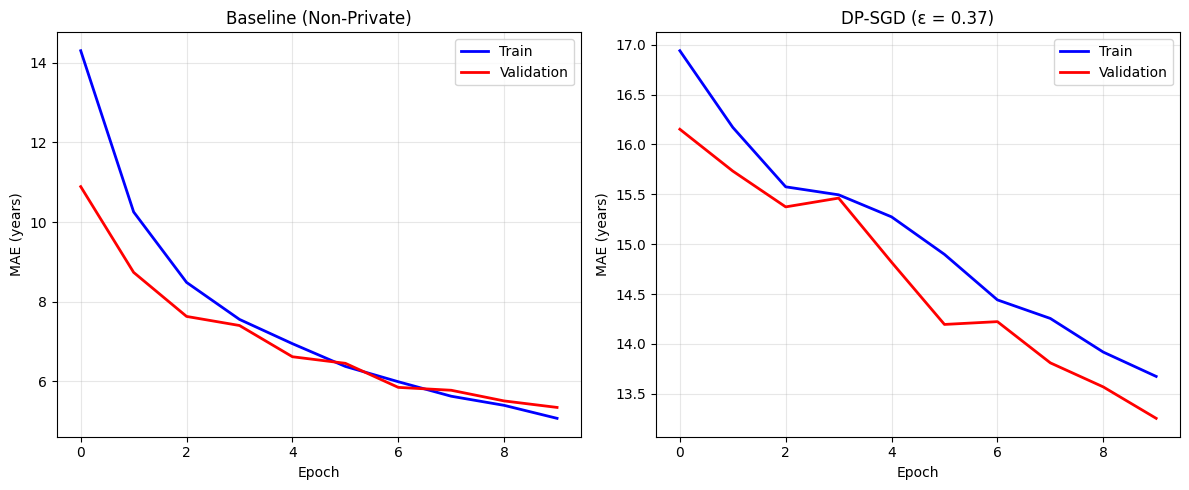

In [2]:
import matplotlib.pyplot as plt

# Data from your training logs
baseline_train = [14.300, 10.253, 8.485, 7.556, 6.947, 6.376, 5.992, 5.628, 5.399, 5.073]
baseline_val = [10.889, 8.736, 7.631, 7.403, 6.619, 6.454, 5.850, 5.778, 5.510, 5.347]
dp_train = [16.939, 16.171, 15.575, 15.495, 15.274, 14.898, 14.442, 14.256, 13.919, 13.675]
dp_val = [16.152, 15.733, 15.374, 15.462, 14.820, 14.196, 14.224, 13.811, 13.570, 13.255]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(baseline_train, 'b-', label='Train', linewidth=2)
plt.plot(baseline_val, 'r-', label='Validation', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('MAE (years)')
plt.title('Baseline (Non-Private)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(dp_train, 'b-', label='Train', linewidth=2)
plt.plot(dp_val, 'r-', label='Validation', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('MAE (years)')
plt.title(f'DP-SGD (ε = {0.37:.2f})')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('project/experiments/exp_20260602_202744/training_curves.png', dpi=150)
plt.show()

In [ ]:
# ============================================================
# 9.  WHITE-BOX AUDIT (Steinke et al. 2023, Algorithm 2) - WITH PROGRESS PRINTING
# ============================================================

def white_box_audit(model, train_loader, canary_idx, n_shadows=8, 
                    epochs=5, delta=1e-5, device='cuda'):
    """
    White-box membership inference audit using cumulative per-sample gradients.
    Implements Algorithm 2 from Steinke et al. 2023.
    """
    print("\n" + "="*60)
    print("WHITE‑BOX AUDIT (Steinke et al. 2023, Algorithm 2)")
    print("="*60)
    sys.stdout.flush()
    
    criterion = nn.L1Loss()
    scores_in, scores_out = [], []
    
    # Get canary data once
    print("Preparing canary data...")
    canary_img, canary_age, _ = train_loader.dataset.dataset[canary_idx]
    canary_img = canary_img.unsqueeze(0).to(device)
    canary_age = canary_age.to(device)
    print(f"Canary index: {canary_idx}")
    sys.stdout.flush()
    
    for shadow_id in range(n_shadows):
        print(f"\n[Shadow {shadow_id+1}/{n_shadows}] Creating model...")
        sys.stdout.flush()
        
        # Create fresh shadow model
        shadow = build_model(pretrained=True)
        optimizer = optim.Adam(shadow.parameters(), lr=1e-3)
        
        # Randomly decide if canary is in training set
        canary_in = random.random() < 0.5
        print(f"[Shadow {shadow_id+1}/{n_shadows}] Canary IN: {canary_in}")
        sys.stdout.flush()
        
        # Build training indices
        train_indices = []
        dataset_len = len(train_loader.dataset)
        
        for idx in range(dataset_len):
            actual_idx = train_loader.dataset.indices[idx] if hasattr(train_loader.dataset, 'indices') else idx
            if actual_idx == canary_idx:
                if canary_in:
                    train_indices.append(actual_idx)
            else:
                train_indices.append(actual_idx)
        
        print(f"[Shadow {shadow_id+1}/{n_shadows}] Training set size: {len(train_indices)}")
        sys.stdout.flush()
        
        # Create shadow loader
        shadow_dataset = Subset(train_loader.dataset.dataset, train_indices)
        shadow_loader = DataLoader(shadow_dataset, batch_size=BATCH_SIZE, 
                                   shuffle=True, num_workers=NUM_WORKERS)
        
        # Record initial loss for canary
        with torch.no_grad():
            init_pred = shadow(canary_img)
            init_loss = criterion(init_pred, canary_age).item()
        print(f"[Shadow {shadow_id+1}/{n_shadows}] Initial loss: {init_loss:.4f}")
        sys.stdout.flush()
        
        # Training
        shadow.train()
        cumulative_grad_norm = 0.0
        
        for epoch in range(epochs):
            batch_count = 0
            for batch_imgs, batch_ages, batch_indices in shadow_loader:
                batch_imgs, batch_ages = batch_imgs.to(device), batch_ages.to(device)
                optimizer.zero_grad()
                preds = shadow(batch_imgs)
                loss = criterion(preds, batch_ages)
                loss.backward()
                
                # Check if canary is in this batch
                canary_in_batch = canary_idx in [idx.item() for idx in batch_indices]
                
                if canary_in_batch and canary_in:
                    # Compute gradient norm
                    grad_norm = 0.0
                    for param in shadow.parameters():
                        if param.grad is not None:
                            grad_norm += param.grad.norm().item() ** 2
                    cumulative_grad_norm += np.sqrt(grad_norm)
                
                optimizer.step()
                batch_count += 1
                
                if batch_count % 50 == 0:
                    print(f"  Epoch {epoch+1}/{epochs}: Processed {batch_count} batches")
                    sys.stdout.flush()
            
            print(f"  Epoch {epoch+1}/{epochs} complete")
            sys.stdout.flush()
        
        # Final loss
        with torch.no_grad():
            final_pred = shadow(canary_img)
            final_loss = criterion(final_pred, canary_age).item()
        
        score = init_loss - final_loss
        
        if canary_in:
            scores_in.append(score)
            print(f"[Shadow {shadow_id+1}/{n_shadows}] CANARY IN - Score: {score:.4f}, Grad norm: {cumulative_grad_norm:.4f}")
        else:
            scores_out.append(score)
            print(f"[Shadow {shadow_id+1}/{n_shadows}] CANARY OUT - Score: {score:.4f}, Grad norm: {cumulative_grad_norm:.4f}")
        sys.stdout.flush()
        
        del shadow
        torch.cuda.empty_cache()
    
    # Compute epsilon
    scores_in = np.array(scores_in)
    scores_out = np.array(scores_out)
    
    print(f"\nScores IN: {scores_in}")
    print(f"Scores OUT: {scores_out}")
    sys.stdout.flush()
    
    if len(scores_in) == 0 or len(scores_out) == 0:
        print("⚠ Insufficient scores for audit")
        return 0.0, 0.0, 0.0
    
    # Find optimal threshold
    all_scores = np.concatenate([scores_in, scores_out])
    thresholds = np.percentile(all_scores, np.linspace(0, 100, 50))
    
    best_tpr, best_fpr = 0, 0
    for threshold in thresholds:
        tpr = np.mean(scores_in >= threshold)
        fpr = np.mean(scores_out >= threshold)
        if tpr - fpr > best_tpr - best_fpr:
            best_tpr, best_fpr = tpr, fpr
    
    if best_fpr > delta:
        epsilon_lower_bound = np.log((best_tpr - delta) / (best_fpr - delta))
    else:
        epsilon_lower_bound = np.log((best_tpr - delta) / delta)
    
    print(f"\n📊 White-box audit results:")
    print(f"  Shadow models: {n_shadows}")
    print(f"  TPR = {best_tpr:.3f}, FPR = {best_fpr:.3f}")
    print(f"  ε ≥ {epsilon_lower_bound:.3f} (δ = {delta})")
    sys.stdout.flush()
    
    return epsilon_lower_bound, best_tpr, best_fpr


# ============================================================
# 10. BLACK-BOX AUDIT - WITH PROGRESS PRINTING
# ============================================================

def black_box_audit(model, train_loader, canary_idx, n_shadows=8, 
                    poison_frac=0.5, epochs=5, delta=1e-5, device='cuda'):
    """
    Black-box membership inference audit using shadow models.
    """
    print("\n" + "="*60)
    print("BLACK‑BOX AUDIT (Steinke et al. 2023, Corollary 5.4)")
    print("="*60)
    sys.stdout.flush()
    
    criterion = nn.L1Loss()
    scores_in, scores_out = [], []
    
    # Get canary data once
    print("Preparing canary data...")
    canary_img, canary_age, _ = train_loader.dataset.dataset[canary_idx]
    canary_img = canary_img.unsqueeze(0).to(device)
    canary_age = canary_age.to(device)
    print(f"Canary index: {canary_idx}")
    sys.stdout.flush()
    
    for shadow_id in range(n_shadows):
        print(f"\n[Shadow {shadow_id+1}/{n_shadows}] Creating model...")
        sys.stdout.flush()
        
        # Create fresh shadow model
        shadow = build_model(pretrained=True)
        optimizer = optim.Adam(shadow.parameters(), lr=1e-3)
        
        # Bernoulli membership for canary
        canary_in = random.random() < poison_frac
        print(f"[Shadow {shadow_id+1}/{n_shadows}] Canary IN: {canary_in}")
        sys.stdout.flush()
        
        # Build training set
        train_indices = []
        dataset_len = len(train_loader.dataset)
        
        for idx in range(dataset_len):
            actual_idx = train_loader.dataset.indices[idx] if hasattr(train_loader.dataset, 'indices') else idx
            if actual_idx == canary_idx:
                if canary_in:
                    train_indices.append(actual_idx)
            else:
                train_indices.append(actual_idx)
        
        print(f"[Shadow {shadow_id+1}/{n_shadows}] Training set size: {len(train_indices)}")
        sys.stdout.flush()
        
        # Create shadow loader
        shadow_dataset = Subset(train_loader.dataset.dataset, train_indices)
        shadow_loader = DataLoader(shadow_dataset, batch_size=BATCH_SIZE, 
                                   shuffle=True, num_workers=NUM_WORKERS)
        
        # Record initial loss
        with torch.no_grad():
            init_pred = shadow(canary_img)
            init_loss = criterion(init_pred, canary_age).item()
        print(f"[Shadow {shadow_id+1}/{n_shadows}] Initial loss: {init_loss:.4f}")
        sys.stdout.flush()
        
        # Train shadow model
        for epoch in range(epochs):
            batch_count = 0
            for batch_imgs, batch_ages, _ in shadow_loader:
                batch_imgs, batch_ages = batch_imgs.to(device), batch_ages.to(device)
                optimizer.zero_grad()
                preds = shadow(batch_imgs)
                loss = criterion(preds, batch_ages)
                loss.backward()
                optimizer.step()
                batch_count += 1
                
                if batch_count % 50 == 0:
                    print(f"  Epoch {epoch+1}/{epochs}: Processed {batch_count} batches")
                    sys.stdout.flush()
            
            print(f"  Epoch {epoch+1}/{epochs} complete")
            sys.stdout.flush()
        
        # Final loss
        with torch.no_grad():
            final_pred = shadow(canary_img)
            final_loss = criterion(final_pred, canary_age).item()
        
        score = init_loss - final_loss
        
        if canary_in:
            scores_in.append(score)
            print(f"[Shadow {shadow_id+1}/{n_shadows}] CANARY IN - Score: {score:.4f}")
        else:
            scores_out.append(score)
            print(f"[Shadow {shadow_id+1}/{n_shadows}] CANARY OUT - Score: {score:.4f}")
        sys.stdout.flush()
        
        del shadow
        torch.cuda.empty_cache()
    
    # Compute epsilon
    scores_in = np.array(scores_in)
    scores_out = np.array(scores_out)
    
    print(f"\nScores IN: {scores_in}")
    print(f"Scores OUT: {scores_out}")
    sys.stdout.flush()
    
    if len(scores_in) == 0 or len(scores_out) == 0:
        print("⚠ Insufficient scores for audit")
        return 0.0, 0.0, 0.0
    
    # Find optimal threshold
    all_scores = np.concatenate([scores_in, scores_out])
    thresholds = np.percentile(all_scores, np.linspace(0, 100, 50))
    
    best_tpr, best_fpr = 0, 0
    for threshold in thresholds:
        tpr = np.mean(scores_in >= threshold)
        fpr = np.mean(scores_out >= threshold)
        if tpr - fpr > best_tpr - best_fpr:
            best_tpr, best_fpr = tpr, fpr
    
    if best_fpr > delta:
        epsilon_lower_bound = np.log((best_tpr - delta) / (best_fpr - delta))
    else:
        epsilon_lower_bound = np.log((best_tpr - delta) / delta)
    
    print(f"\n📊 Black-box audit results:")
    print(f"  Shadow models: {n_shadows}")
    print(f"  Poison fraction: {poison_frac}")
    print(f"  TPR = {best_tpr:.3f}, FPR = {best_fpr:.3f}")
    print(f"  ε ≥ {epsilon_lower_bound:.3f} (δ = {delta})")
    sys.stdout.flush()
    
    return epsilon_lower_bound, best_tpr, best_fpr


# ============================================================
# SIMPLIFIED MAIN - Run only one audit at a time for debugging
# ============================================================

if __name__ == "__main__":
    import sys
    
    # Update this path
    exp_dir = Path("project/experiments/exp_20260602_202744")
    
    if exp_dir.exists():
        print("="*60)
        print("LOADING EXISTING EXPERIMENT")
        print("="*60)
        
        # Load DP model only
        dp_model = build_model(pretrained=True)
        dp_path = exp_dir / "models" / "dp_best.pth"
        
        if dp_path.exists():
            dp_model = load_opacus_model(dp_model, dp_path, device)
            print("✓ DP model loaded")
        else:
            print(f"⚠ DP model not found at {dp_path}")
            sys.exit(1)
        
        # Test with just 2 shadows first (faster for debugging)
        canary_idx = random.randint(0, len(train_loader.dataset) - 1)
        
        print("\n" + "="*60)
        print("RUNNING WHITE-BOX AUDIT (2 shadows for testing)")
        print("="*60)
        
        try:
            white_eps, white_tpr, white_fpr = white_box_audit(
                dp_model, train_loader, canary_idx, 
                n_shadows=3, epochs=4, delta=1e-5, device=device
            )
            print(f"\n✅ White-box audit complete! ε ≥ {white_eps:.3f}")
        except Exception as e:
            print(f"\n❌ White-box audit failed: {e}")
            import traceback
            traceback.print_exc()
        
        print("\n" + "="*60)
        print("RUNNING BLACK-BOX AUDIT (2 shadows for testing)")
        print("="*60)
        
        try:
            black_eps, black_tpr, black_fpr = black_box_audit(
                dp_model, train_loader, canary_idx, 
                n_shadows=2, poison_frac=0.5, epochs=2, delta=1e-5, device=device
            )
            print(f"\n✅ Black-box audit complete! ε ≥ {black_eps:.3f}")
        except Exception as e:
            print(f"\n❌ Black-box audit failed: {e}")
            import traceback
            traceback.print_exc()
        
    else:
        print(f"Experiment directory not found: {exp_dir}")